# Adult Census Income Classification
## End-to-End Pipeline: Boosting Algorithms, Optuna Tuning, and Stacking Ensembles

---

### Project Overview
The objective of this project is to build an end-to-end machine learning classification system to predict whether an individual's annual income exceeds $50,000 using demographic, education, and employment data from the 1994 U.S. Census Bureau database (UCI Adult Dataset).

**Target Variable (`income`):**
- `0` (`<=50K`): Annual income less than or equal to $50,000.
- `1` (`>50K`): Annual income strictly greater than $50,000.

### Dataset Description
- **Source**: UCI Machine Learning Repository
- **Size**: 32,561 rows and 15 raw features
- **Continuous Features**: `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`
- **Categorical Features**: `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`
- **Target**: `income`

### Pipeline Roadmap
1. **Exploratory Data Analysis (EDA)**: Read-only audit of missing values, class distributions, skewness, and feature correlations.
2. **Data Partitioning**: Stratified Train-Test Split (80% development, 20% hold-out test) prior to any transformations to strictly prevent data leakage.
3. **Feature Engineering & Preprocessing**: Constructing isolated pipelines per algorithm (One-Hot Encoding for XGBoost, native categorical handling for LightGBM and CatBoost, standard scaling for linear estimators).
4. **Hyperparameter Optimization**: Systematic Bayesian tuning using Optuna with Stratified K-Fold Cross-Validation.
5. **Ensemble Methods**: Evaluation and comparison of Voting Classifiers, Blending, and Out-of-Fold (OOF) Stacking with a Logistic Regression meta-learner.

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [29]:
import pandas as pd

# Correct URL to the Census Income dataset on UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# The dataset does not have a header, so we should define the columns
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=columns, skipinitialspace=True)

print(f"Data Shape: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
df.head()

Data Shape: 32,561 Rows | 15 Columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [30]:
# 1. Remove extra whitespace from text values (to ensure detection of '?' or ' ?')
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# 2. Replace any '?' marker with a genuine missing value (NaN)
df = df.replace("?", np.nan)

# 3. Drop the education and fnlwgt columns
df = df.drop(columns=["education", "fnlwgt"], errors="ignore")

# 4. Check and count genuine missing values in each column
missing_summary = pd.DataFrame(
    {
        "Missing Count": df.isnull().sum(),
        "Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

# Display only columns containing missing values
print(f"Data Shape After Drop: {df.shape}")
print("\n--- Missing Values Breakdown ---")
print(missing_summary[missing_summary["Missing Count"] > 0])

Data Shape After Drop: (32561, 13)

--- Missing Values Breakdown ---
                Missing Count  Percentage (%)
workclass                1836            5.64
occupation               1843            5.66
native-country            583            1.79


In [31]:
for i in df.columns:
  print(df[i].value_counts())

age
36    898
31    888
34    886
23    877
35    876
     ... 
83      6
88      3
85      3
86      1
87      1
Name: count, Length: 73, dtype: int64
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education-num
9     10501
10     7291
13     5355
14     1723
11     1382
7      1175
12     1067
6       933
4       646
15      576
5       514
8       433
16      413
3       333
2       168
1        51
Name: count, dtype: int64
marital-status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   education-num   32561 non-null  int64 
 3   marital-status  32561 non-null  object
 4   occupation      30718 non-null  object
 5   relationship    32561 non-null  object
 6   race            32561 non-null  object
 7   sex             32561 non-null  object
 8   capital-gain    32561 non-null  int64 
 9   capital-loss    32561 non-null  int64 
 10  hours-per-week  32561 non-null  int64 
 11  native-country  31978 non-null  object
 12  income          32561 non-null  object
dtypes: int64(5), object(8)
memory usage: 3.2+ MB


In [33]:
df.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,1077.648844,87.303830,40.437456
std,13.640433,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.000000,0.000000,0.000000,1.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000


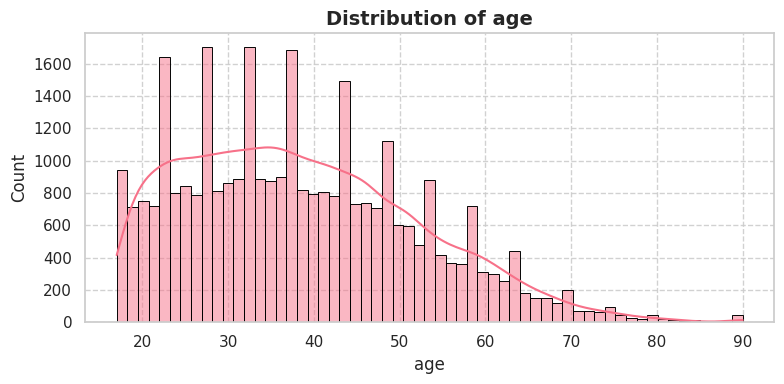

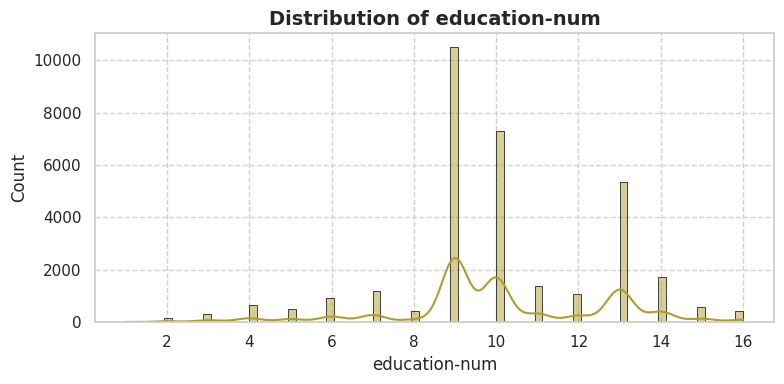

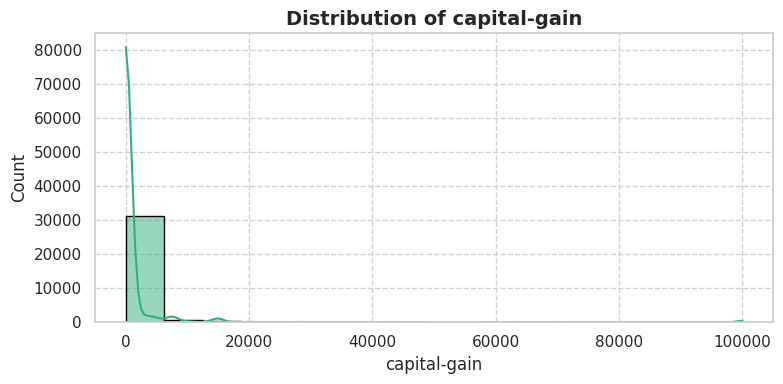

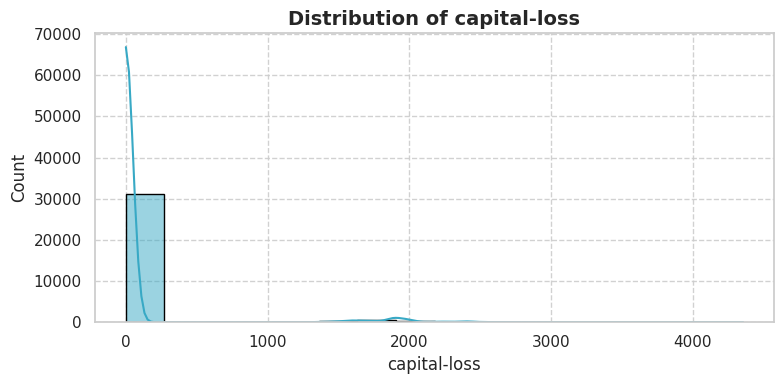

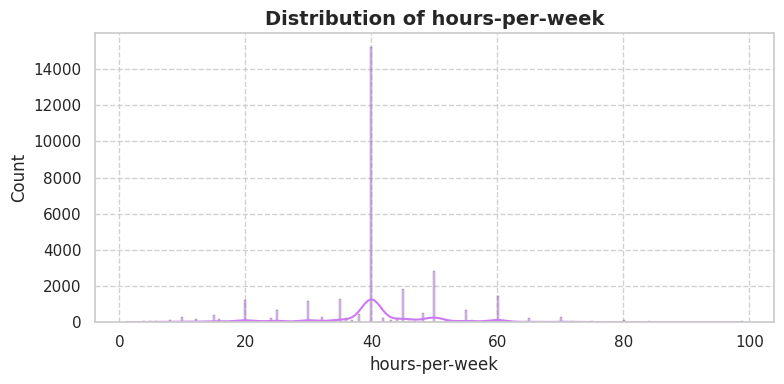

In [34]:
palette = sns.color_palette("husl" , len(df.select_dtypes(include="number").columns))

for idx , col in enumerate(df.select_dtypes(include="number").columns):
  plt.figure(figsize=(8 , 4))
  sns.histplot(data=df , x=col , color=palette[idx] , edgecolor="black" , kde=True)
  plt.title(f"Distribution of {col}" , fontsize=14 , fontweight="bold")
  plt.grid(True , linestyle='--' , alpha=0.9)
  plt.tight_layout()
  plt.show()

In [35]:
# 1. Create a completely separate copy for Exploratory Data Analysis (EDA)
df_eda = df.copy()

# 2. Convert the target variable (income_bracket) into binary values (0 and 1)
df_eda["income"] = (
    df_eda["income"]
    .astype(str)
    .str.rstrip(".")
    .map({"<=50K": 0, ">50K": 1})
)

# 3. Encode categorical (Object) columns into numeric values while preserving NaN
cat_columns = df_eda.select_dtypes(include=["object"]).columns

for col in cat_columns:
    cat_series = df_eda[col].astype("category")
    # Replace -1 (automatically assigned by pandas to NaN) with np.nan to avoid distorting correlation calculations
    df_eda[col] = cat_series.cat.codes.replace(-1, np.nan)

# 4. Ensure that all columns are fully numeric
print("EDA Data Shape:", df_eda.shape)
print("\nColumn Data Types After Encoding:")
print(df_eda.dtypes)
df_eda.head()

EDA Data Shape: (32561, 13)

Column Data Types After Encoding:
age                 int64
workclass         float64
education-num       int64
marital-status       int8
occupation        float64
relationship         int8
race                 int8
sex                  int8
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country    float64
income              int64
dtype: object


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,6.0,13,4,0.0,1,4,1,2174,0,40,38.0,0
1,50,5.0,13,2,3.0,0,4,1,0,0,13,38.0,0
2,38,3.0,9,0,5.0,1,4,1,0,0,40,38.0,0
3,53,3.0,7,2,5.0,0,2,1,0,0,40,38.0,0
4,28,3.0,13,2,9.0,5,2,0,0,0,40,4.0,0


/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


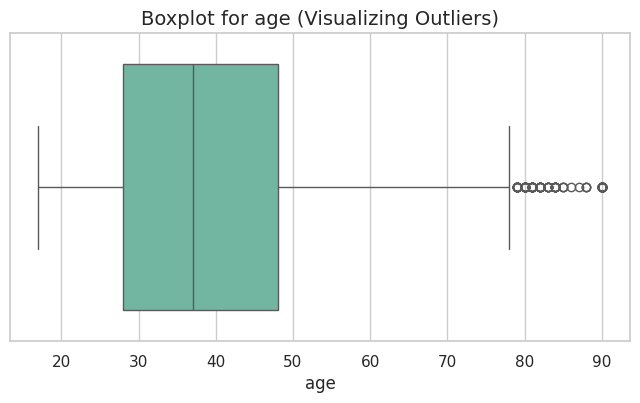

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


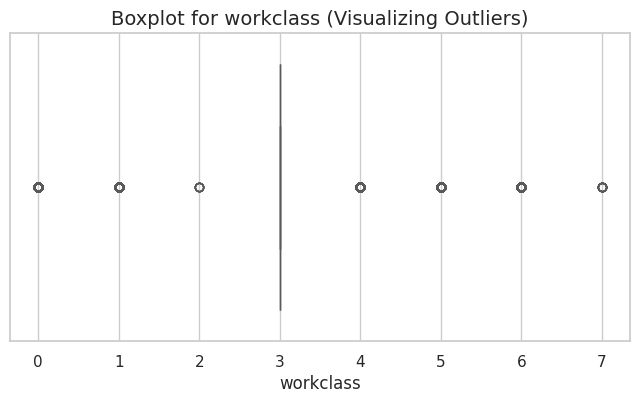

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


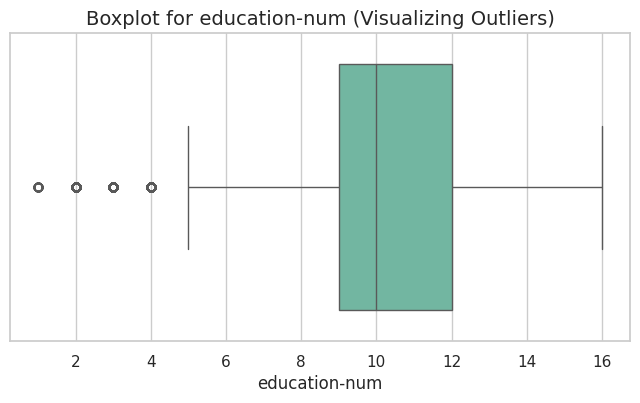

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


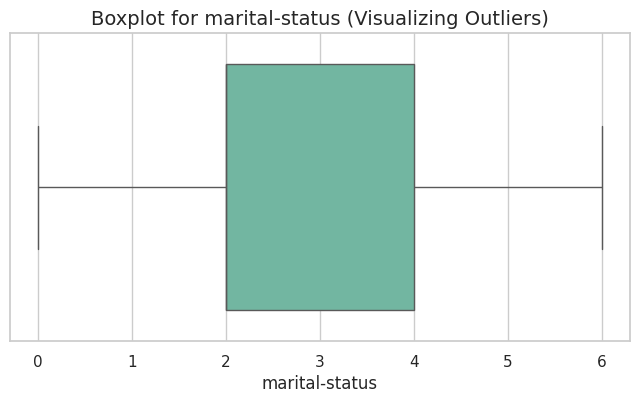

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


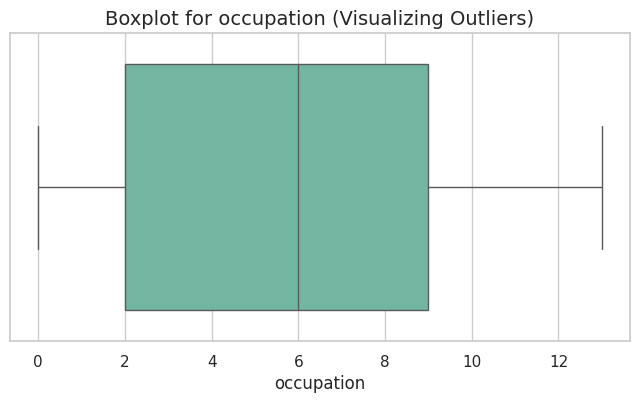

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


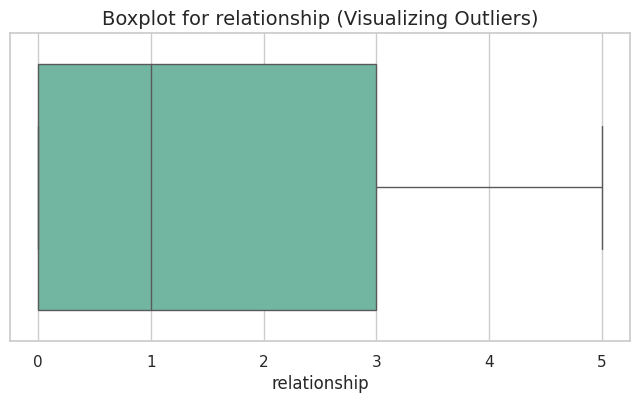

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


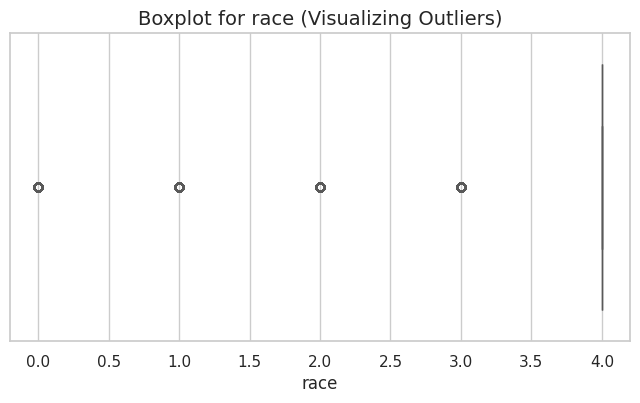

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


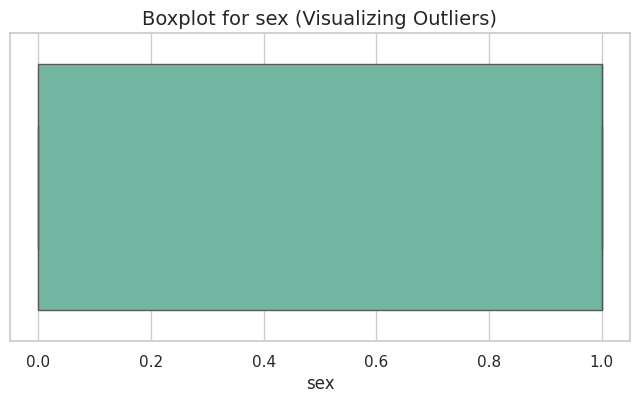

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


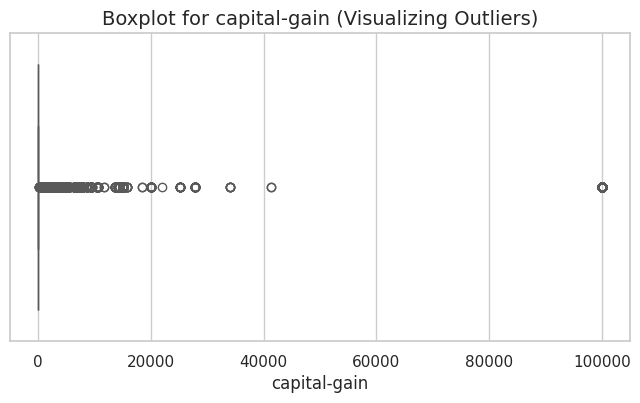

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


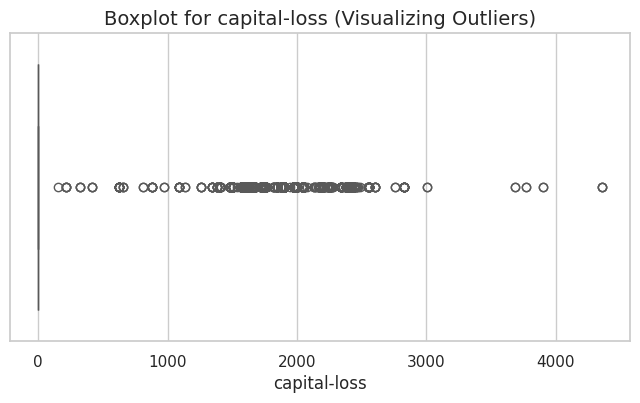

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


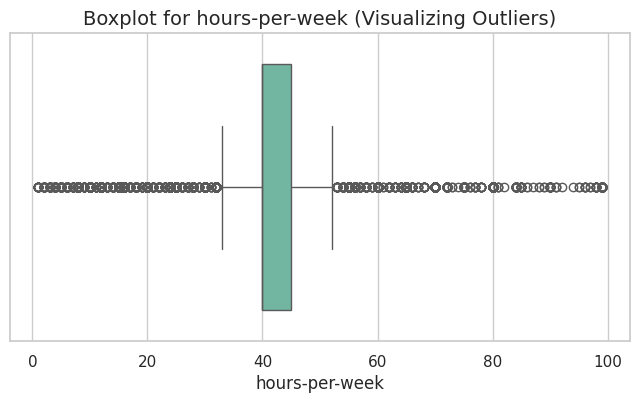

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


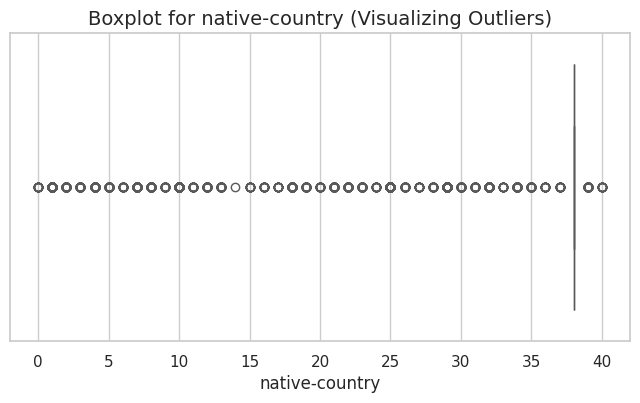

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


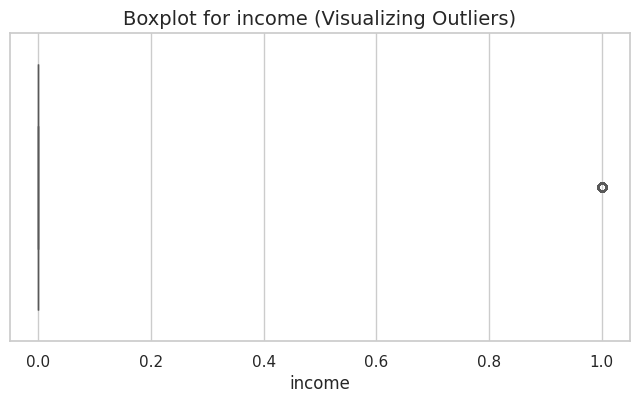

In [36]:
for col in df_eda.columns:
  plt.figure(figsize=(8 , 4))
  sns.boxplot(data=df_eda , x=col , palette="Set2")
  plt.title(f"Boxplot for {col} (Visualizing Outliers)" , fontsize=14)
  plt.show()

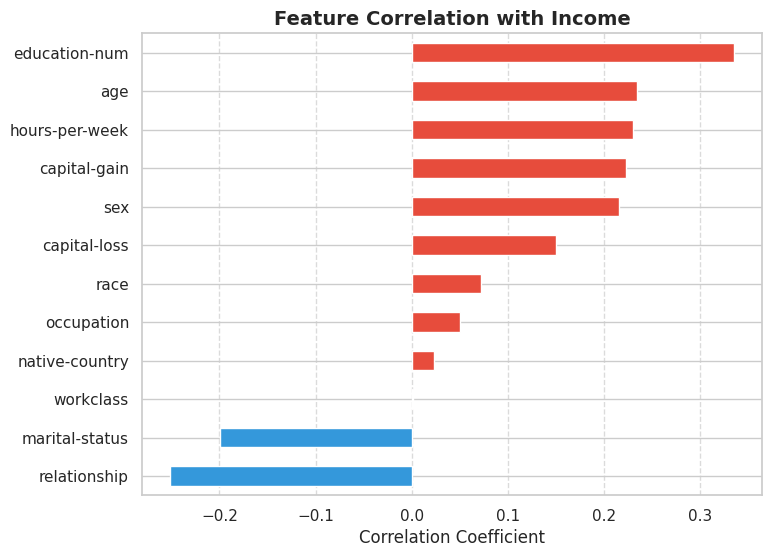

In [37]:
income_corr = df_eda.corr()['income'].drop('income').sort_values(ascending=True)

plt.figure(figsize=(8, 6))
income_corr.plot(kind='barh', color=income_corr.map(lambda x: '#e74c3c' if x > 0 else '#3498db'))
plt.title("Feature Correlation with Income", fontsize=14, fontweight='bold')
plt.xlabel("Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Exploratory Data Analysis: Key Findings and Engineering Decisions

---

### 1. Data Cleaning and Attribute Selection
- **Missing Value Standardization**: Missing entries encoded as `?` were converted to standard `np.nan` across all columns[cite: 1].
- **Redundant Feature Removal**: `education` was dropped due to perfect collinearity with `education-num`, which provides the equivalent ordinal numerical scale[cite: 1].
- **Noise Reduction**: `fnlwgt` (final sampling weight) was removed because it reflects census survey weights rather than individual predictive behavioral characteristics[cite: 1].

### 2. Missing Values Audit
- Missing values are strictly confined to three categorical attributes:
  - `occupation`: 1,843 missing values (5.66%)[cite: 1]
  - `workclass`: 1,836 missing values (5.64%)[cite: 1]
  - `native-country`: 583 missing values (1.79%)[cite: 1]
- All continuous numerical features contain zero missing values[cite: 1].
- **Decision**: Missing categories will be handled via frequent-value imputation inside model-specific pipelines strictly after the train-test split to avoid data leakage.

### 3. Class Imbalance Assessment
- **Class Distribution**:
  - `<=50K`: 24,720 samples (75.92%)[cite: 1]
  - `>50K`: 7,841 samples (24.08%)[cite: 1]
- **Imbalance Ratio**: Approximately 3.15 : 1.
- **Decision**:
  - Accuracy will not be used as the primary metric; model selection will prioritize **ROC-AUC**, PR-AUC, and F1-Score.
  - Stratification will be enforced across all splits (`StratifiedKFold`).
  - The `scale_pos_weight` parameter will be configured in boosting models to adjust for class proportions.

### 4. Continuous Feature Distributions and Outliers
- **Capital Features**: `capital-gain` (91.6% zero values) and `capital-loss` (95.3% zero values) display severe positive skewness, with outliers extending up to 99,999[cite: 1].
- **Working Hours**: `hours-per-week` peaks around 40 hours (mean: 40.43, standard deviation: 12.35), with tails reflecting part-time and overtime employment[cite: 1].
- **Age**: Moderately right-skewed across ages 17 to 90, with a median of 37 years[cite: 1].
- **Decision**: Tree-based gradient boosting models are invariant to monotonic transformations and naturally robust to isolated outliers. Outliers will not be arbitrarily removed; instead, derived binary indicators will be engineered.

### 5. Correlation and Key Predictors
- **Numerical Features**: The strongest linear correlation with `income` is `education-num` (+0.34), followed by `age` (+0.23), `hours-per-week` (+0.23), and `capital-gain` (+0.22).
- **Categorical Patterns**:
  - `marital-status`: Married individuals (`Married-civ-spouse`) show a substantially higher probability of earning `>50K` compared to unmarried individuals[cite: 1].
  - `native-country`: High cardinality with 41 unique countries, heavily dominated by `United-States` (89.58%)[cite: 1].

### 6. Feature Engineering Blueprint
- **Capital Adjustments**:
  - `capital_net` = `capital-gain` - `capital-loss`
  - `has_capital_gain` = Binary flag (`capital-gain > 0`)
  - `has_capital_loss` = Binary flag (`capital-loss > 0`)
- **Categorical Consolidation**:
  - `native-country`: Group into binary categories (`United-States` vs. `Non-US`).
  - `marital-status`: Consolidate into high-level categories (`Married` vs. `Single_or_Divorced`).

---

### Next Phase: Stratified Partitioning and Model Pipelines
The dataset will now be divided into an 80% development set and a 20% hold-out test set using `StratifiedShuffleSplit`. Separate preprocessing pipelines will then be built for XGBoost, LightGBM, and CatBoost.